In [58]:
from sympy import *
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [59]:
#list of necessary parameters
parameters = {
    'm': 1,      #mass, kg
    'g': 9.81,   #acceleration due to gravity, m/s^2
    'Ct': 1,     #Thrust coefficient
    'Cm': 1,     #Moment coefficient
    'Ixx': 1,    #Inertia in x, kg*m^2
    'Iyy': 1,    #Inertia in y, kg*m^2
    'Izz': 1,    #Inertia in z, kg*m^2
    'L': 1       #Length of arm, m   
}

In [60]:
#Controller mixer matrix
def mix(T, taux, tauy, tauz, parameters):
   
    Ct = parameters['Ct']
    Cm = parameters['Cm']
    L = parameters['L']
    
#find torque to thrust ratio
    c = Cm / Ct

#perpendicular distance from center to motor
    d = L / np.sqrt(2)
    
#find the mixer matrix
    B = np.array([
        [1, 1, 1, 1],
        [-d, d, d, -d],
        [-d, -d, d, d],
        [c, -c, c, -c]
    ])
    
#define commanded thrust and torque
    Tcmd = np.array([T, taux, tauy, tauz]) #heave, roll, pitch, yaw
    
#define propeller thrust and torque
    Tprop = np.linalg.solve(B, Tcmd)
    Tprop = np.clip(Tprop, 0, None)
    
#convert propeller thrust to angular velocity
    omega = np.sqrt(Tprop / Ct)
    return omega

s = mix(5, 5, 5, 5, parameters)
print(s)

[0.         0.         2.45673236 0.        ]


In [61]:
#Equations of motion
def eoms(t, u, parameters, controller):

#current state of the drone
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u

#find angular velocity of each motor
    omega = controller(t, u, parameters)
    omega1, omega2, omega3, omega4 = omega
    
    m = parameters['m']
    g = parameters['g']
    Ct = parameters['Ct']
    Cm = parameters['Cm']
    L = parameters['L']
    Ixx = parameters['Ixx']
    Iyy = parameters['Iyy']
    Izz = parameters['Izz']

#calculate motor thrusts and torques
    T1 = Ct * omega1**2
    T2 = Ct * omega2**2
    T3 = Ct * omega3**2
    T4 = Ct * omega4**2
    Ttot = T1 + T2 + T3 + T4
#roll, pitch, and yaw torques
    taux = d * (-T1 + T2 + T3 - T4)
    tauy = d * (-T1 - T2 + T3 + T4)
    tauz = (Cm / Ct) * (T1 - T2 + T3 - T4)

#linear accelerations
    ax = (Ttot/m) * (np.cos(psi)*np.sin(theta)*np.cos(phi) + np.sin(psi)*np.sin(phi))
    ay = (Ttot/m) * (np.sin(psi)*np.sin(theta)*np.cos(phi) - np.cos(psi)*np.sin(phi))
    az = (Ttot/m) * np.cos(theta)*np.cos(phi) - g

#angular accelerations
    p_dot = (taux + (Iyy - Izz)*q*r) / Ixx
    q_dot = (tauy + (Izz - Ixx)*p*r) / Iyy
    r_dot = (tauz + (Ixx - Iyy)*p*q) / Izz

#euler angle rates
    phi_dot = p + (q*np.sin(phi) + r*np.cos(phi))*np.tan(theta)
    theta_dot = q*np.cos(phi) - r*np.sin(phi)
    psi_dot = (q*np.sin(phi) + r*np.cos(phi))/np.cos(theta)

    return np.array([vx, vy, vz, ax, ay, az, phi_dot, theta_dot, psi_dot, p_dot, q_dot, r_dot])

In [68]:
#Controller
def control(t, u, parameters, ref_func):

#current state
    x, y, z, vx, vy, vz, phi, theta, psi, p, q, r = u

    m = parameters['m']
    g = parameters['g']
    Ixx = parameters['Ixx']
    Iyy = parameters['Iyy']
    Izz = parameters['Izz']

#desired positions and velocities
    xref, yref, zref, psiref, vxref, vyref, vzref = ref_func(t)

#position controller gains
    Kp_pos = 2.0
    Kd_pos = 2.0
    Kp_z = 5.0
    Kd_z = 4.0

#desired linear accelerations
    ax_des = Kp_pos*(xref - x) + Kd_pos*(vxref - vx)
    ay_des = Kp_pos*(yref - y) + Kd_pos*(vyref - vy)
    az_des = Kp_z*(zref - z) + Kd_z*(vzref - vz)

#total thrust command
    T = m*(g + az_des)/(np.cos(phi)*np.cos(theta))
    T = np.clip(T, 0, None)

#desired pitch and roll angles
    theta_des = (ax_des*np.cos(psi) + ay_des*np.sin(psi))/g
    phi_des = (ax_des*np.sin(psi) - ay_des*np.cos(psi))/g

#limit desired angles to 25 degrees
    max_angle = np.radians(25)
    theta_des = np.clip(theta_des, -max_angle, max_angle)
    phi_des = np.clip(phi_des, -max_angle, max_angle)

#attitude controller gains
    Kp_att = 10.0
    Kd_att = 5.0
    Kp_yaw = 5.0
    Kd_yaw = 2.0

#desired angular accelerations
    p_dot_des = Kp_att*(phi_des - phi) - Kd_att*p
    q_dot_des = Kp_att*(theta_des - theta) - Kd_att*q

#yaw control
    psi_error = (psiref - psi + np.pi) % (2*np.pi) - np.pi
    r_dot_des = Kp_yaw*psi_error - Kd_yaw*r

#required torques
    taux = Ixx*p_dot_des - (Iyy - Izz)*q*r
    tauy = Iyy*q_dot_des - (Izz - Ixx)*p*r
    tauz = Izz*r_dot_des - (Ixx - Iyy)*p*q

#convert thrust and torques to motor speeds
    return mix(T, taux, tauy, tauz, parameters)


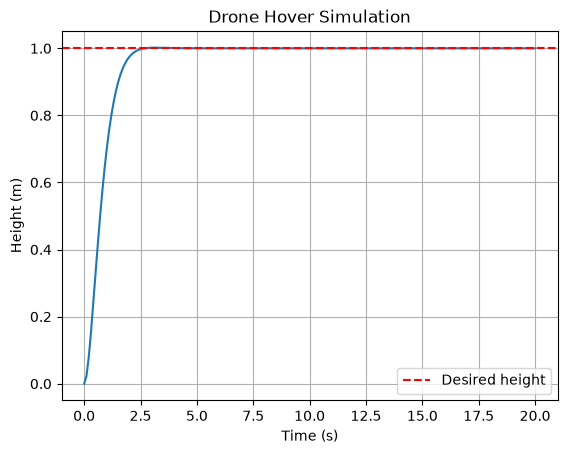

In [69]:
#Hover at 1 m
def ref_hover(t):
    return 0, 0, 1, 0, 0, 0, 0

#initial conditions
u0 = np.zeros(12)

#simulation
sol = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_hover)
    ),
    (0, 20),
    u0,
    t_eval=np.linspace(0, 20, 200)
)

#plot
plt.plot(sol.t, sol.y[2])
plt.axhline(1, color='red', linestyle='--', label='Desired height')
plt.xlabel('Time (s)')
plt.ylabel('Height (m)')
plt.title('Drone Hover Simulation')
plt.legend()
plt.grid()
plt.show()

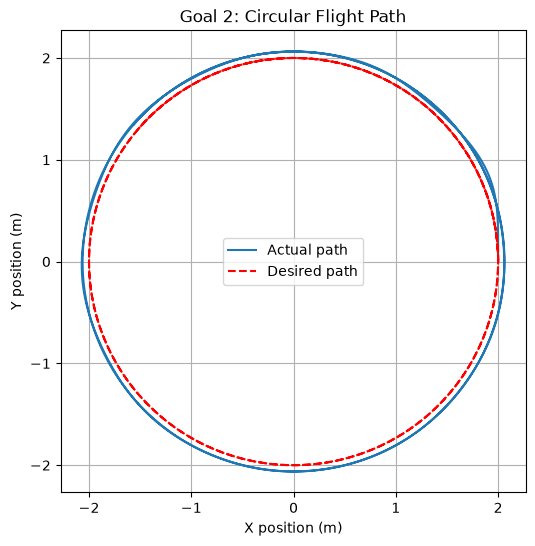

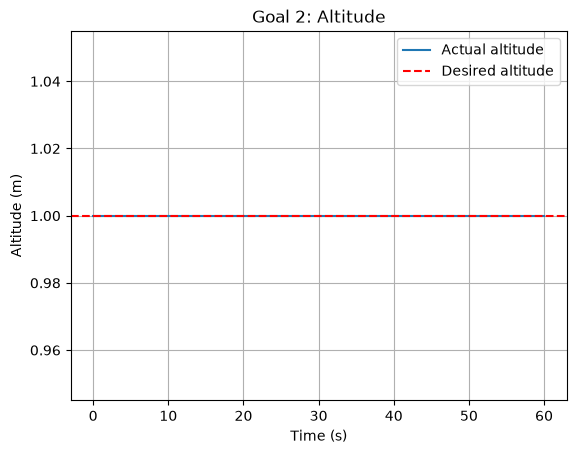

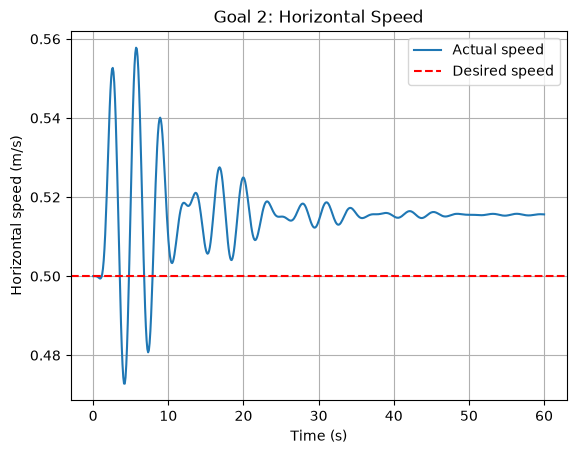

In [70]:
#Circle at 0.5m/s with a radius of 2m
def ref_circle(t):

    R = 2.0      #radius of circular path, m
    v = 0.5      #horizontal speed, m/s

    omega = v / R

#desired positions
    xref = R * np.cos(omega*t)
    yref = R * np.sin(omega*t)
    zref = 1.0                     #altitude, m

#desired yaw angle
    psiref = 0

#desired velocities
    vxref = -R*omega*np.sin(omega*t)
    vyref = R*omega*np.cos(omega*t)
    vzref = 0

    return xref, yref, zref, psiref, vxref, vyref, vzref

#initial conditions
u0_circle = np.zeros(12)

u0_circle[0] = 2.0    #initial x position, m
u0_circle[1] = 0.0    #initial y position, m
u0_circle[2] = 1.0    #initial altitude, m

u0_circle[3] = 0.0    #initial x velocity, m/s
u0_circle[4] = 0.5    #initial y velocity, m/s
u0_circle[5] = 0.0    #initial z velocity, m/s

#simulation
sol_circle = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_circle)
    ),
    (0, 60),
    u0_circle,
    t_eval=np.linspace(0, 60, 600),
    method='RK45'
)

#plot
t = np.linspace(0, 60, 600)

xref = 2*np.cos(0.25*t)
yref = 2*np.sin(0.25*t)

plt.figure(figsize=(6, 6))
plt.plot(sol_circle.y[0], sol_circle.y[1], label='Actual path')
plt.plot(xref, yref, 'r--', label='Desired path')

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.title('Goal 2: Circular Flight Path')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

plt.plot(sol_circle.t, sol_circle.y[2], label='Actual altitude')
plt.axhline(1.0, color='red', linestyle='--', label='Desired altitude')

plt.xlabel('Time (s)')
plt.ylabel('Altitude (m)')
plt.title('Goal 2: Altitude')
plt.legend()
plt.grid()
plt.show()

#calculate horizontal speed
vx = sol_circle.y[3]
vy = sol_circle.y[4]

v_horizontal = np.sqrt(vx**2 + vy**2)

#plot speed
plt.plot(sol_circle.t, v_horizontal, label='Actual speed')
plt.axhline(0.5, color='red', linestyle='--', label='Desired speed')

plt.xlabel('Time (s)')
plt.ylabel('Horizontal speed (m/s)')
plt.title('Goal 2: Horizontal Speed')
plt.legend()
plt.grid()
plt.show()

The solver successfully reached the end of the integration interval.


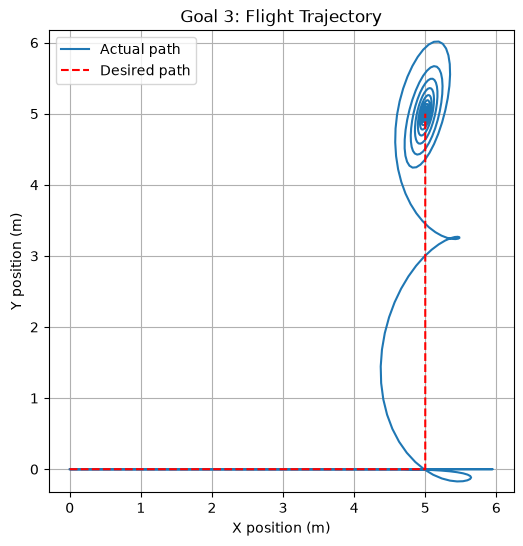

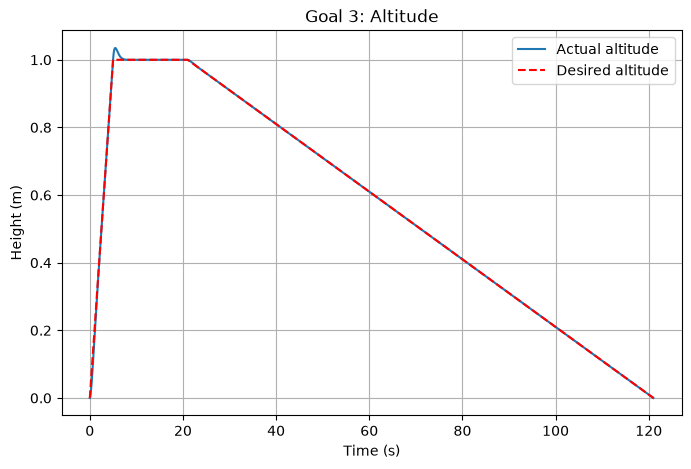

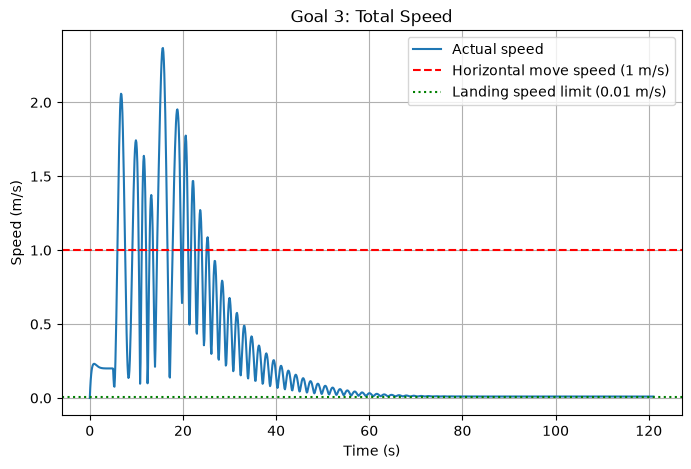

Ground reached at: 121.0 seconds
Vertical speed: 0.00978467403360015 m/s
Total speed: 0.009784688444440961 m/s


In [71]:
#Flight trajectory
def ref_traj(t):

#time of each maneuver, s
    t_ascend = 5
    t_move1 = 5
    t_wait1 = 2
    t_yaw = 2
    t_move2 = 5
    t_wait2 = 2
    t_land = 100

#end times of each maneuver
    T1 = t_ascend
    T2 = T1 + t_move1
    T3 = T2 + t_wait1
    T4 = T3 + t_yaw
    T5 = T4 + t_move2
    T6 = T5 + t_wait2
    T7 = T6 + t_land

#initially at the origin
    xref = 0
    yref = 0
    zref = 0
    psiref = 0

    vxref = 0
    vyref = 0
    vzref = 0

#ascend to 1 m
    if t < T1:
        zref = t / t_ascend
        vzref = 1 / t_ascend

#move forward 5 m in x
    elif t < T2:
        dt = t - T1
        xref = dt / t_move1 * 5
        zref = 1
        vxref = 5 / t_move1

#stop and hover
    elif t < T3:
        xref = 5
        zref = 1

#yaw 90 degrees left
    elif t < T4:
        dt = t - T3
        xref = 5
        zref = 1
        psiref = dt / t_yaw * (np.pi / 2)

#go forward 5 m in y
    elif t < T5:
        dt = t - T4
        xref = 5
        yref = dt / t_move2 * 5
        zref = 1
        psiref = np.pi / 2
        vyref = 5 / t_move2

#stop and hover
    elif t < T6:
        xref = 5
        yref = 5
        zref = 1
        psiref = np.pi / 2

#land vertically
    elif t < T7:
        dt = t - T6
        xref = 5
        yref = 5
        zref = 1 - dt / t_land
        psiref = np.pi / 2
        vzref = -1 / t_land

#final position
    else:
        xref = 5
        yref = 5
        zref = 0
        psiref = np.pi / 2

    return xref, yref, zref, psiref, vxref, vyref, vzref

#initial conditions
u0_traj = np.zeros(12)

#simulation
sol_traj = solve_ivp(
    lambda t, u: eoms(
        t, u, parameters,
        lambda t, u, p: control(t, u, p, ref_traj)
    ),
    (0, 121),
    u0_traj,
    t_eval=np.linspace(0, 121, 1211),
    method='RK45',
    max_step=0.1
)

print(sol_traj.message)

#desired path
xref = []
yref = []

for t in sol_traj.t:
    x, y, z, psi, vx, vy, vz = ref_traj(t)
    xref.append(x)
    yref.append(y)

#plot
plt.figure(figsize=(6, 6))

plt.plot(sol_traj.y[0], sol_traj.y[1], label='Actual path')
plt.plot(xref, yref, 'r--', label='Desired path')

plt.xlabel('X position (m)')
plt.ylabel('Y position (m)')
plt.title('Goal 3: Flight Trajectory')
plt.axis('equal')
plt.legend()
plt.grid()
plt.show()

zref = []

for t in sol_traj.t:
    x, y, z, psi, vx, vy, vz = ref_traj(t)
    zref.append(z)

plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, sol_traj.y[2], label='Actual altitude')
plt.plot(sol_traj.t, zref, 'r--', label='Desired altitude')

plt.xlabel('Time (s)')
plt.ylabel('Height (m)')
plt.title('Goal 3: Altitude')
plt.legend()
plt.grid()
plt.show()

#calculate total speed
vx = sol_traj.y[3]
vy = sol_traj.y[4]
vz = sol_traj.y[5]

v_total = np.sqrt(vx**2 + vy**2 + vz**2)

plt.figure(figsize=(8, 5))

plt.plot(sol_traj.t, v_total, label='Actual speed')
plt.axhline(1.0, color='red', linestyle='--',
            label='Horizontal move speed (1 m/s)')
plt.axhline(0.01, color='green', linestyle=':',
            label='Landing speed limit (0.01 m/s)')

plt.xlabel('Time (s)')
plt.ylabel('Speed (m/s)')
plt.title('Goal 3: Total Speed')
plt.legend()
plt.grid()
plt.show()

#find landing during final descent
landing_indices = np.where(
    (sol_traj.t >= 21) & (sol_traj.y[2] <= 0)
)[0]

if len(landing_indices) > 0:
    i = landing_indices[0]

    print("Ground reached at:", sol_traj.t[i], "seconds")
    print("Vertical speed:", abs(sol_traj.y[5, i]), "m/s")
    print("Total speed:", v_total[i], "m/s")
else:
    print("Drone did not reach the ground during the simulation.")
    print("Final altitude:", sol_traj.y[2, -1], "m")